# 3) Análise Comparativa — VisDrone e MVRSD

Os notebooks anteriores examinaram cada dataset separadamente. Aqui, colocamos os resultados lado a lado para entender as diferenças entre as **cenas aéreas de trânsito do VisDrone** e as **imagens de veículos militares e civis do MVRSD**.

A comparação concentra-se nas características que afetam a detecção e a formação dos recortes: distribuição das classes, tamanho das caixas, densidade de veículos e resolução das imagens. Isso ajuda a contextualizar o uso desses dados no projeto.

Os números do VisDrone vêm das tabelas e dos resultados salvos no notebook `01_eda_visdrone.ipynb`, ou dos seus arquivos CSV/JSON quando disponíveis. Os resultados do MVRSD vêm da análise do notebook `02_eda_mvrsd.ipynb`. A origem usada em cada execução aparece na célula seguinte.

In [ ]:
from pathlib import Path
import json
import sys

REPO_ROOT = next(
    folder for folder in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (folder / "configs/default.yaml").is_file()
)
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))
from vehicle_recognition.configuration import configure_environment
configure_environment(REPO_ROOT)
import pandas as pd
from IPython.display import Image as IPyImage, display

from vehicle_recognition.eda_comparison import run_eda_comparison

OUT_DIR = REPO_ROOT / "outputs/eda_comparison"
FIG_DIR = OUT_DIR / "figures"
comparison_summary = run_eda_comparison(REPO_ROOT, OUT_DIR)
print(json.dumps(comparison_summary["sources"], indent=2, ensure_ascii=False))


/tmp/drone-roboflow-venv/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


{
  "visdrone": {
    "kind": "executed_notebook_outputs",
    "file": "notebooks/01_eda_visdrone.ipynb",
    "sha256": "f4cee7f385df21aebe31216560fa9886adca75164a7b571de92ad1c0c481bd7c",
    "note": "Historical saved HTML tables and JSON stdout; raw VisDrone images were not reprocessed. Percentages and geometry statistics retain the rounding of those saved outputs."
  },
  "mvrsd": {
    "kind": "native_json_csv",
    "file": "outputs/eda_mvrsd/eda_mvrsd_summary.json",
    "sha256": "30bd80637e2e2d647a5f92f93acc4bc7de42f5454cf3831ef9d273d6c4e69626"
  }
}


---
## 1. Composição dos Dois Datasets

A análise do VisDrone abrange **7.019 imagens**, com **381.963 objetos anotados**. Desse total, **205.663** são veículos das classes `car`, `van`, `truck` e `bus`, selecionadas pelo detector do projeto.

No MVRSD, analisamos **3.000 imagens** e **32.629 veículos**. Todas as suas cinco classes representam veículos, distribuídos por tamanho e função.

A tabela distingue o total de objetos do total de veículos e apresenta os splits considerados. Essa distinção importa porque o VisDrone também contém pedestres, bicicletas, motocicletas e outras categorias.

In [ ]:
scope_df = pd.read_csv(OUT_DIR / "dataset_scope.csv")
display(scope_df)


,dataset,images,annotated_images,all_valid_boxes,vehicle_boxes,scope,vehicle_taxonomy
0,VisDrone,7019,7019,381963,205663,VisDrone2019-DET (train + val; saved notebook ...,"car, van, truck, bus"
1,MVRSD,3000,3000,32629,32629,"train, val","SMV, LMV, AFV, MCV, CV"


---
## 2. Distribuição das Classes e Desbalanceamento

Os dois conjuntos têm uma classe majoritária, mas descrevem os veículos de maneiras diferentes:

- No **VisDrone**, `car` concentra **77,28% dos veículos selecionados**. As outras três classes de veículos aparecem em proporções bem menores.
- No **MVRSD**, `CV` é a maior classe isolada, com **41,97%** das anotações. As quatro categorias militares, juntas, representam **58,03%**.
- `MCV`, com **941 exemplos (2,88%)**, é a categoria menos frequente do MVRSD.

Os gráficos mantêm os nomes originais. Uma categoria como SMV não corresponde diretamente a `car`: o critério de tamanho e função militar é diferente da divisão entre tipos de veículos do VisDrone. Cada percentual usa o total de anotações do respectivo dataset.

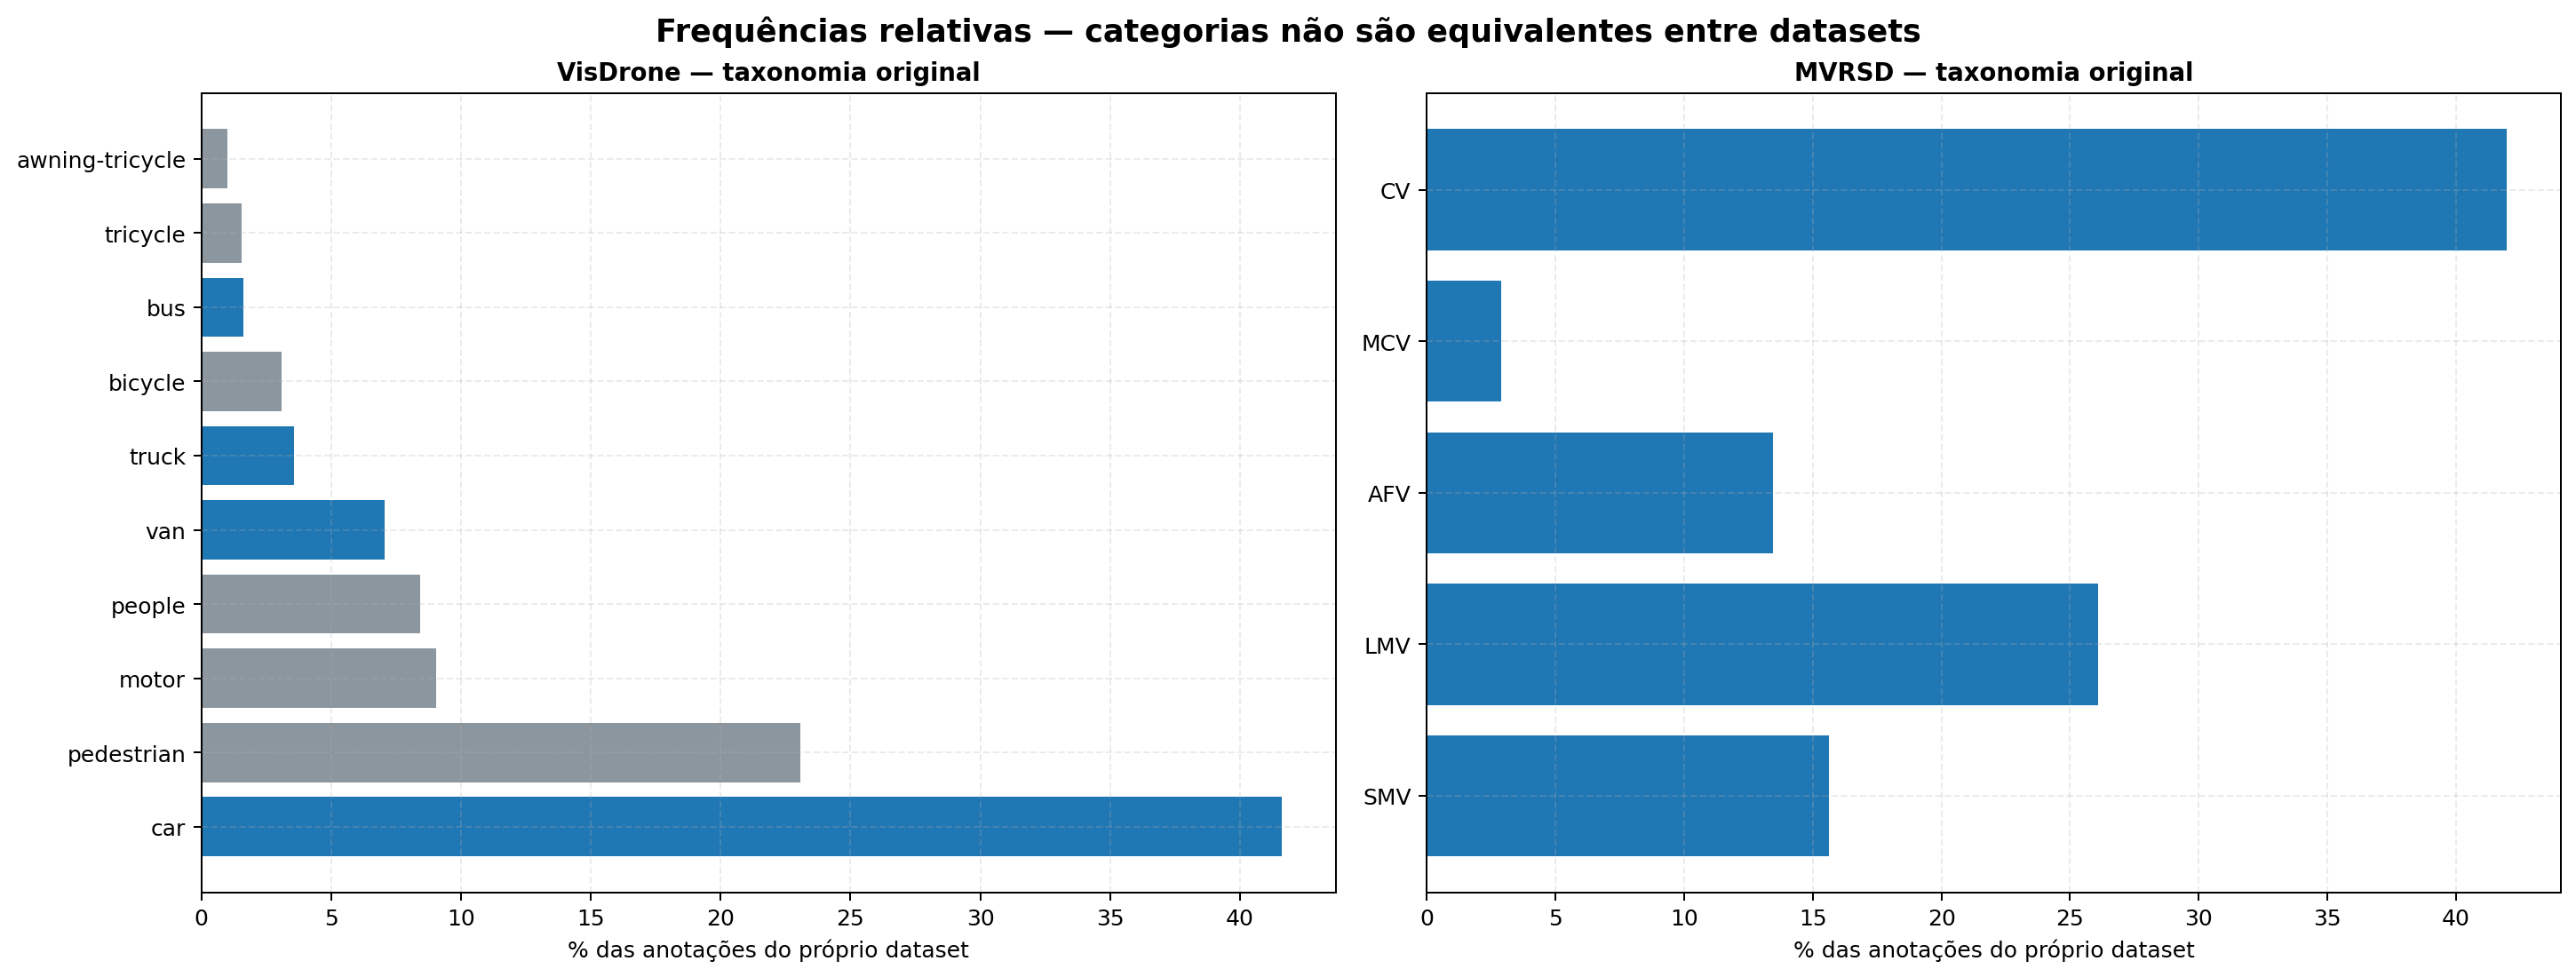

In [ ]:
display(IPyImage(filename=str(FIG_DIR / "01_class_taxonomies.png"), width=1200))


---
## 3. Tamanho dos Veículos e Área Ocupada na Imagem

As caixas do MVRSD ocupam, em geral, uma parcela maior do enquadramento. Isso fica claro na comparação das áreas relativas medianas, mas também é importante olhar as dimensões em pixels.

Por exemplo, **SMV tem mediana de 38 × 39 pixels**, próxima dos **38 × 29 pixels de `car` no VisDrone**. Já a área relativa mediana é de **0,325%** para SMV e **0,076%** para `car`. Esses valores ilustram como a resolução da imagem muda o peso de um objeto no enquadramento, mesmo quando sua largura em pixels é parecida.

Nas classes LMV, AFV e MCV, mais de **88% das caixas** estão na faixa *Medium* do critério COCO. No VisDrone, a parcela de caixas *Small* chega a **48,26% em `car`** e **43,34% em `van`**. A tabela detalha as medidas de cada classe e os gráficos mostram essas diferenças de escala.

,dataset,class_name,median_width_px,median_height_px,median_rel_area_pct,median_aspect_ratio,small_pct,medium_pct,large_pct
0,VisDrone,car,38.0,29.0,0.0761,1.2500,48.2600,43.7300,8.0000
1,VisDrone,van,39.0,34.0,0.0928,1.1200,43.3400,46.2700,10.3900
2,VisDrone,truck,49.0,43.0,0.1500,1.0400,31.3600,52.1000,16.5400
3,VisDrone,bus,48.0,47.0,0.1849,0.9400,28.7000,54.5900,16.7100
4,MVRSD,SMV,38.0,39.0,0.3247,0.9600,20.7140,79.1095,0.1765
5,MVRSD,LMV,56.0,61.0,0.7471,0.8429,3.5257,88.3418,8.1326
6,MVRSD,AFV,50.0,56.0,0.6152,0.8533,3.0780,95.2348,1.6872
7,MVRSD,MCV,48.0,57.0,0.6240,0.8148,2.2317,96.3868,1.3815
8,MVRSD,CV,36.0,39.0,0.3125,0.9048,27.3019,72.2015,0.4965


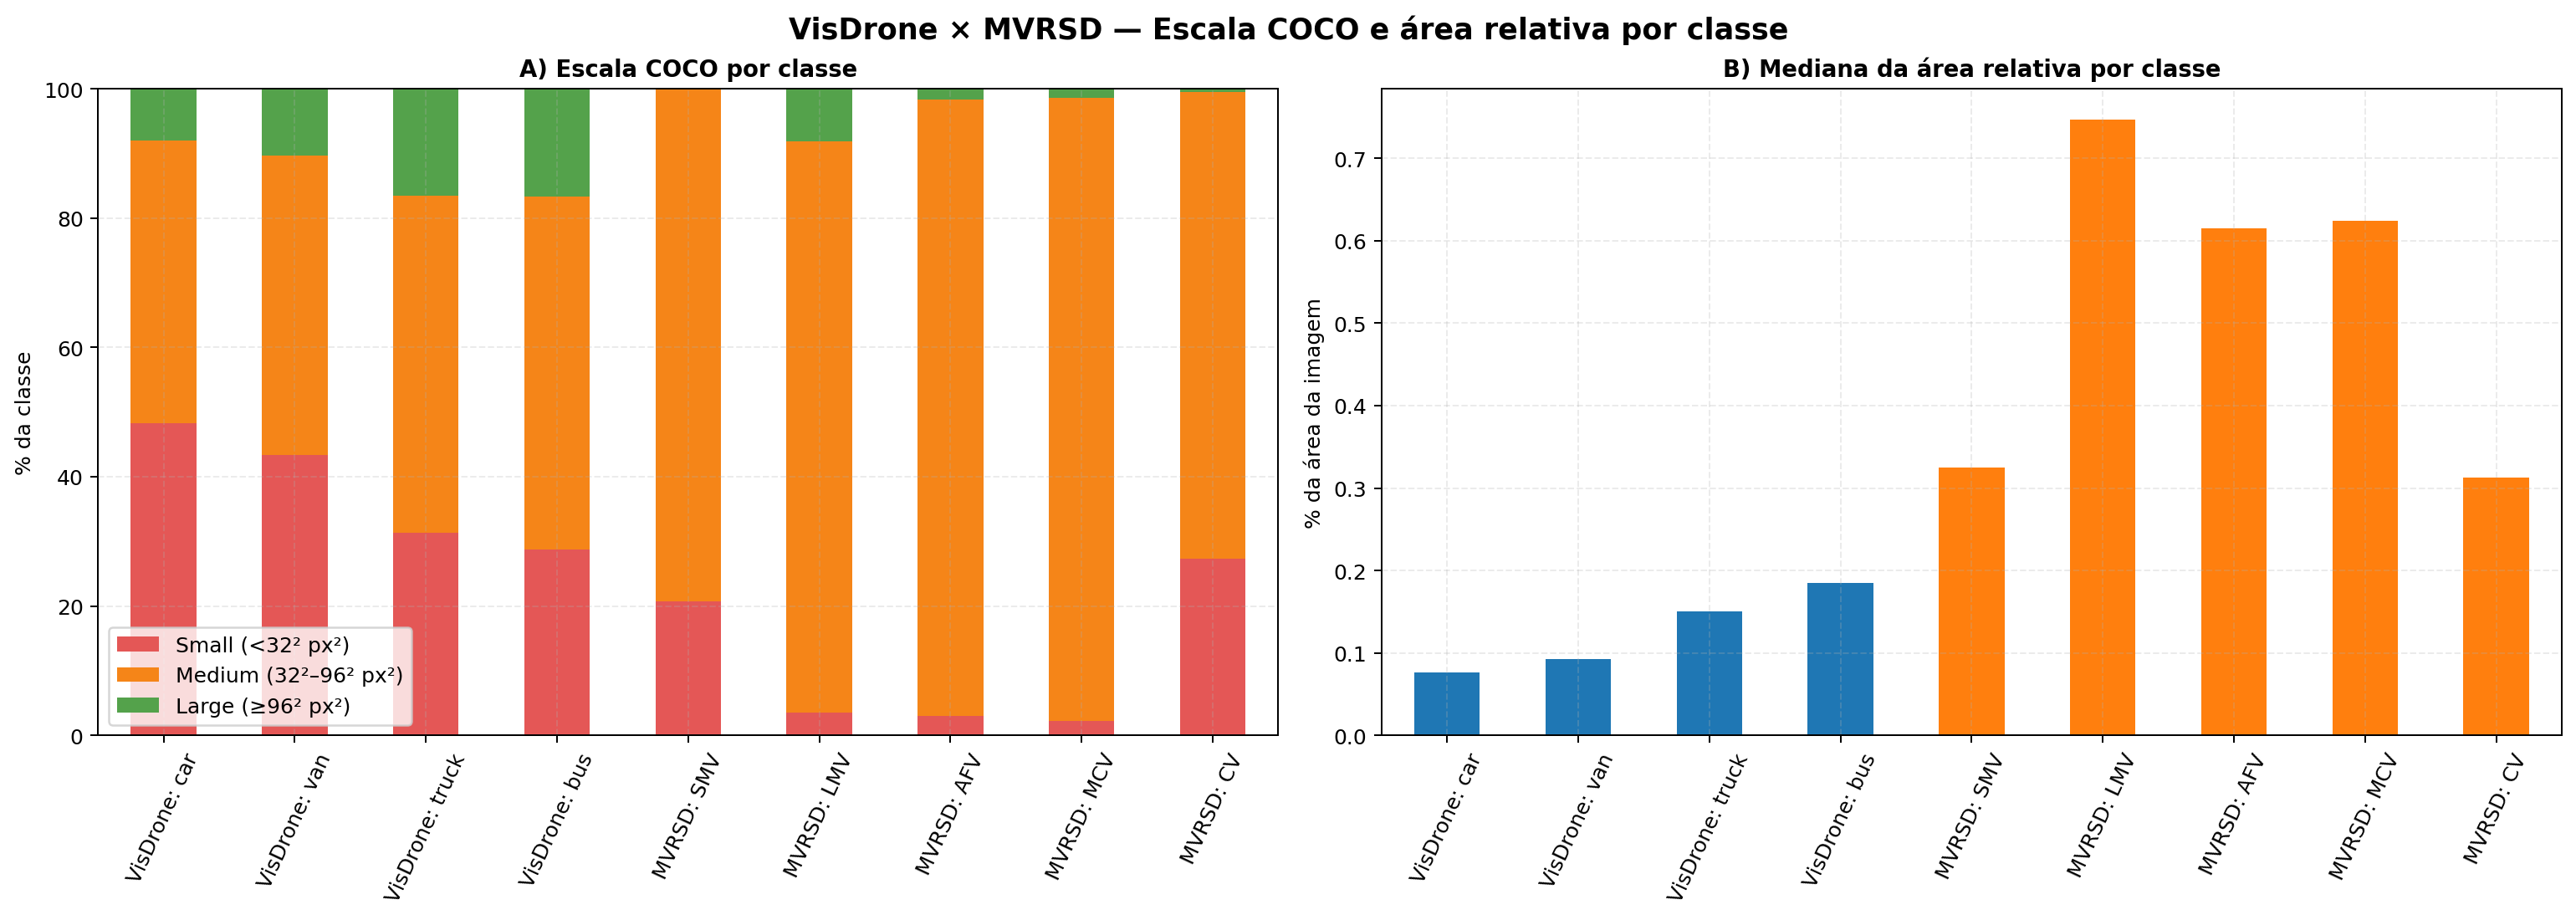

In [ ]:
geometry_df = pd.read_csv(OUT_DIR / "vehicle_box_geometry.csv")
columns = ["dataset", "class_name", "median_width_px", "median_height_px", "median_rel_area_pct",
           "median_aspect_ratio", "small_pct", "medium_pct", "large_pct"]
display(geometry_df[columns].round(4))
display(IPyImage(filename=str(FIG_DIR / "02_vehicle_scale_and_relative_area.png"), width=1250))


---
## 4. Densidade das Cenas e Razão de Aspecto

As cenas do VisDrone são mais povoadas nesta análise:

| Medida | VisDrone — veículos selecionados | MVRSD |
| --- | ---: | ---: |
| Média de veículos por imagem | 29,30 | 10,88 |
| Mediana | 22 | 6 |
| Percentil 90 | 63 | 27 |
| Maior contagem em uma imagem | 349 | 119 |

Em ambos, algumas cenas com muitos veículos elevam a média acima da mediana. O efeito é especialmente visível no MVRSD, em que metade das imagens contém até seis veículos.

O segundo painel compara a razão de aspecto mediana das caixas. Essa medida ajuda a descrever o formato dos recortes que chegam à etapa de similaridade, embora também seja influenciada pela orientação do veículo na imagem.

,statistic,VisDrone,MVRSD
0,mean,29.3,10.876333
1,median,22.0,6.000000
2,p90,63.0,27.000000
3,max,349.0,119.000000


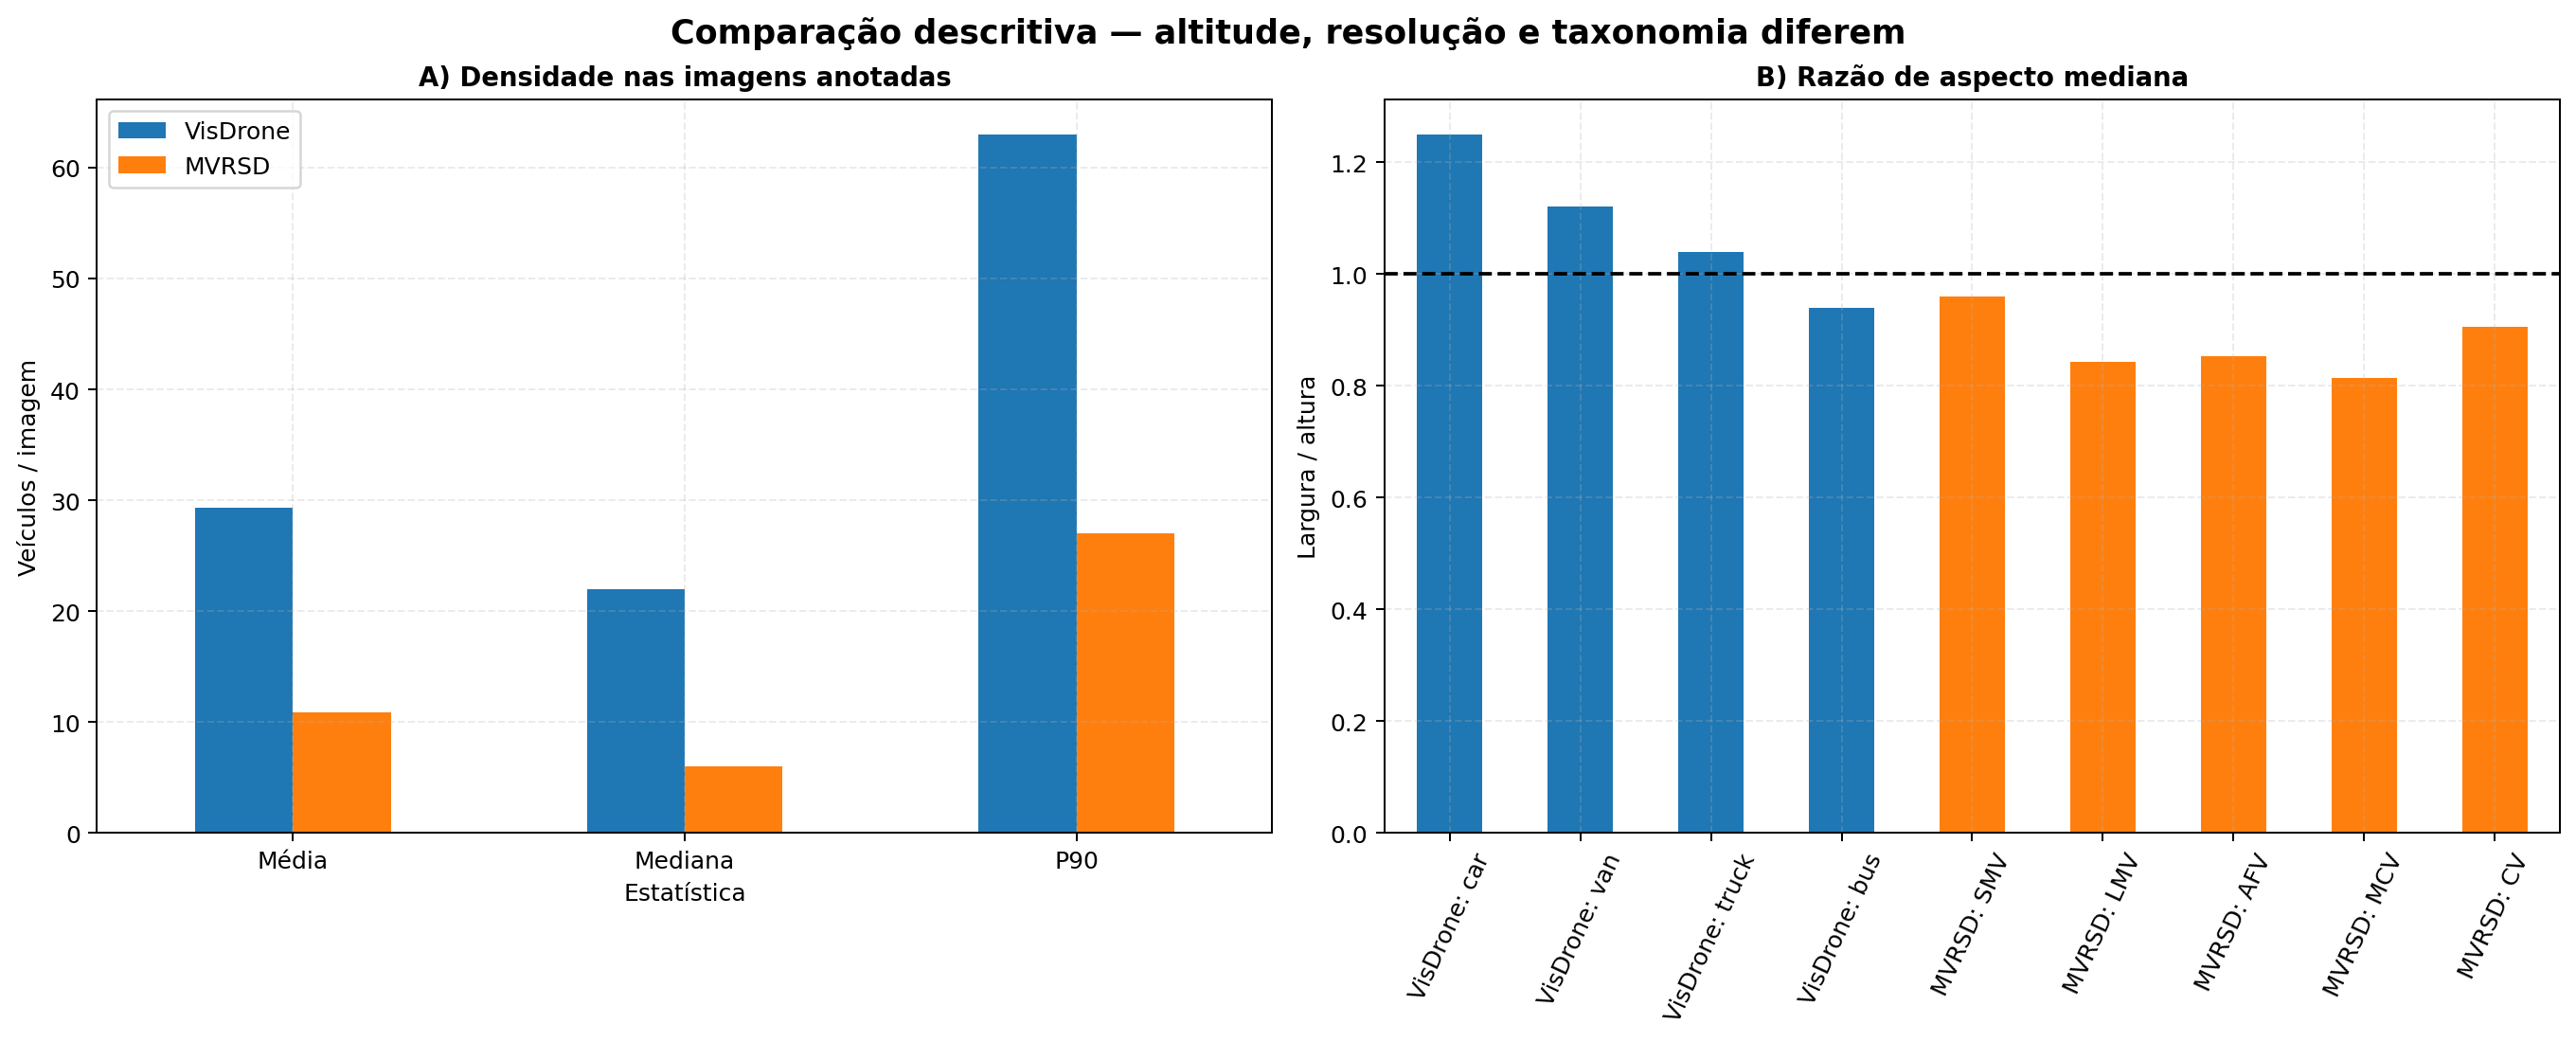

In [ ]:
display(pd.read_csv(OUT_DIR / "vehicle_density.csv"))
display(IPyImage(filename=str(FIG_DIR / "03_density_and_aspect_ratios.png"), width=1200))


---
## 5. Resoluções das Imagens

O VisDrone apresenta **11 resoluções**, com predomínio de **1400 × 1050 pixels**. O MVRSD é mais uniforme: **2.996 das 3.000 imagens** medem **640 × 640 pixels**, e as outras quatro diferem por poucos pixels.

Essa diferença ajuda a interpretar os gráficos de área relativa. Uma caixa de determinado tamanho em pixels ocupa uma fração maior de uma imagem de 640 × 640 do que de uma imagem de 1400 × 1050.

No gráfico do VisDrone, as resoluções que não aparecem individualmente no resumo salvo foram agrupadas em **Outras resoluções**. A tabela de metadados, logo abaixo, retoma os campos disponíveis no MVRSD.

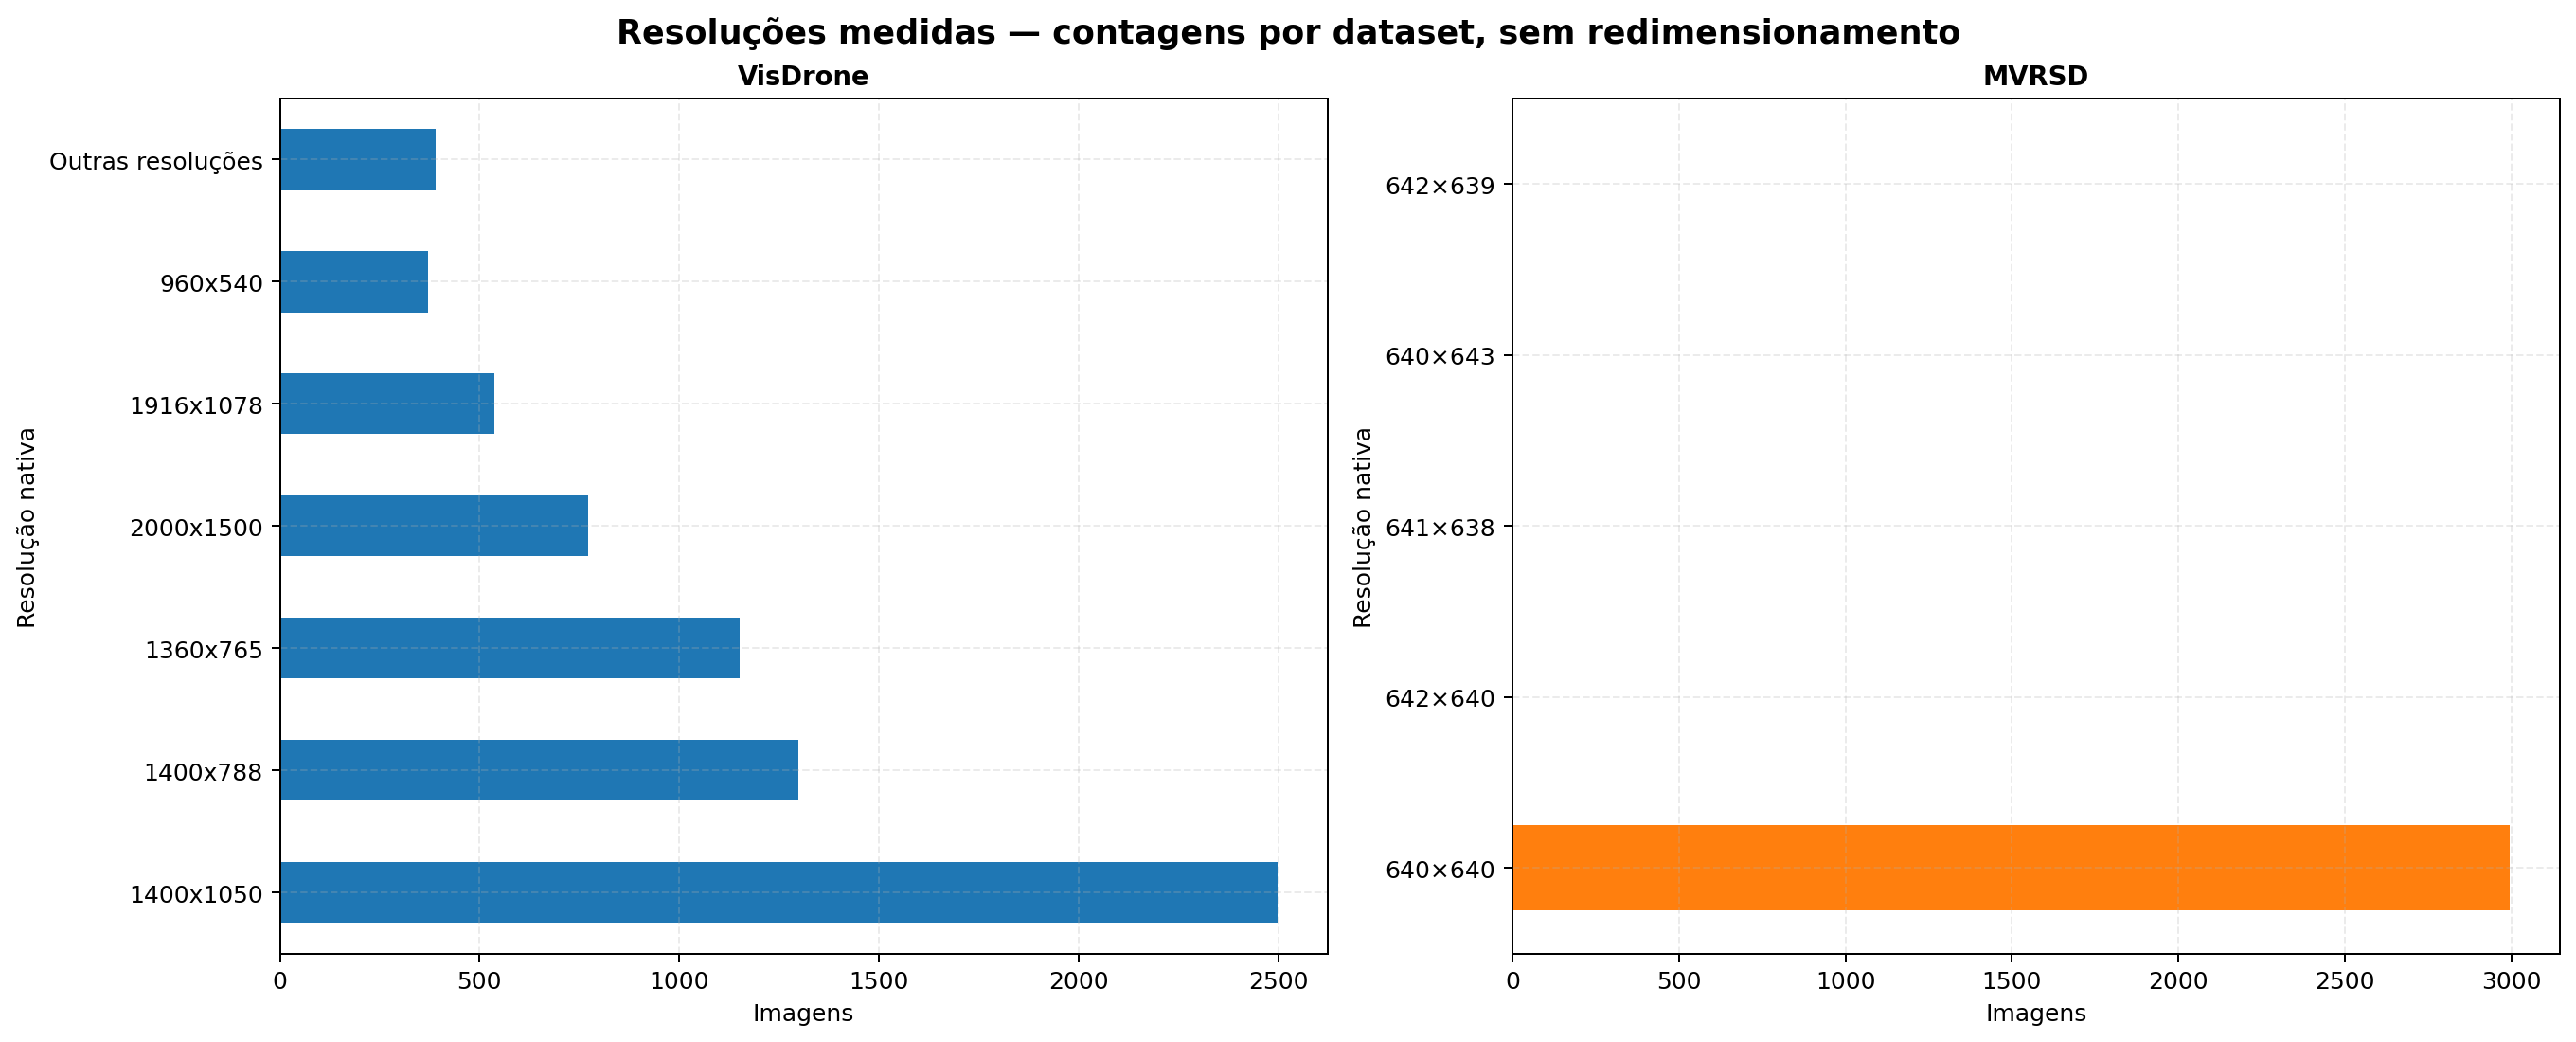

,boxes_with_field,values
truncated,32629,{'0': 32629}
difficult,32629,{'0': 32629}
occluded,0,{}


In [ ]:
display(IPyImage(filename=str(FIG_DIR / "04_native_resolutions.png"), width=1150))
display(pd.DataFrame.from_dict(comparison_summary["mvrsd_metadata_availability"], orient="index"))


---
## 6. Oclusão, Tipos de Cena e Relação com o Pipeline

O VisDrone permite separar veículos por grau de oclusão e truncamento. No MVRSD, não há um campo de oclusão equivalente, e os valores de `truncated` e `difficult` estão todos zerados. Por isso, a comparação dessas dificuldades depende também da observação das cenas nos notebooks individuais.

| Aspecto | VisDrone | MVRSD |
| --- | --- | --- |
| Origem das imagens | Capturas aéreas por drones | Google Earth |
| Categorias | Dez classes; quatro de veículos selecionadas no pipeline | Cinco classes de veículos militares e civis |
| Formato mais comum das imagens | 1400 × 1050 pixels | 640 × 640 pixels |
| Densidade média de veículos | 29,30 por imagem | 10,88 por imagem |
| Exemplos de detecção | Notebook 01 | Notebook 02 |

Para o projeto, os conjuntos oferecem exemplos com características diferentes de escala, densidade e aparência. A identificação de um modelo operacional, porém, continua sendo uma etapa posterior à detecção: o recorte precisa ser comparado com a galeria simulada.

As predições mostradas no notebook MVRSD ajudam a examinar os checkpoints, mas podem envolver imagens usadas no treino. A avaliação em floresta é que permanece reservada à verificação do desempenho no cenário final.

Fontes MVRSD: [dataset](https://doi.org/10.57760/sciencedb.j00240.00036) e [artigo original](https://www.cjig.cn/en/article/doi/10.11834/jig.230884/).

---
## 7. Síntese da Comparação

O **VisDrone** reúne mais veículos por cena e uma participação maior de caixas pequenas nas classes `car` e `van`. O **MVRSD** acrescenta categorias militares, imagens de tamanho mais uniforme e caixas que ocupam uma parcela maior do enquadramento.

As diferenças observadas ajudam a entender o que cada conjunto oferece ao detector. Elas também mostram por que o resultado global precisa ser acompanhado da análise por classe e por tipo de cena. Para os gráficos e textos do projeto, as tabelas desta comparação ficam em `outputs/eda_comparison/`.

In [7]:
print("Origem dos resultados:")
print(json.dumps(comparison_summary["sources"], indent=2, ensure_ascii=False))
print("Arquivos da comparação:")
for path in sorted(OUT_DIR.glob("*")):
    print(" -", path.relative_to(REPO_ROOT))


Origem dos resultados:
{
  "visdrone": {
    "kind": "executed_notebook_outputs",
    "file": "notebooks/01_eda_visdrone.ipynb",
    "sha256": "f4cee7f385df21aebe31216560fa9886adca75164a7b571de92ad1c0c481bd7c",
    "note": "Historical saved HTML tables and JSON stdout; raw VisDrone images were not reprocessed. Percentages and geometry statistics retain the rounding of those saved outputs."
  },
  "mvrsd": {
    "kind": "native_json_csv",
    "file": "outputs/eda_mvrsd/eda_mvrsd_summary.json",
    "sha256": "30bd80637e2e2d647a5f92f93acc4bc7de42f5454cf3831ef9d273d6c4e69626"
  }
}
Arquivos da comparação:
 - outputs/eda_comparison/dataset_scope.csv
 - outputs/eda_comparison/eda_comparison_summary.json
 - outputs/eda_comparison/figures
 - outputs/eda_comparison/vehicle_box_geometry.csv
 - outputs/eda_comparison/vehicle_density.csv
